In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from src.functions_generator import FunctionsGenerator

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

# Test generazione dataset di funzioni

Genero un dataset di funzioni usando "generate_random_f_from_white_noise". In seguito tratto le funzioni generate come vettori e calcolo la matrice di correlazione.

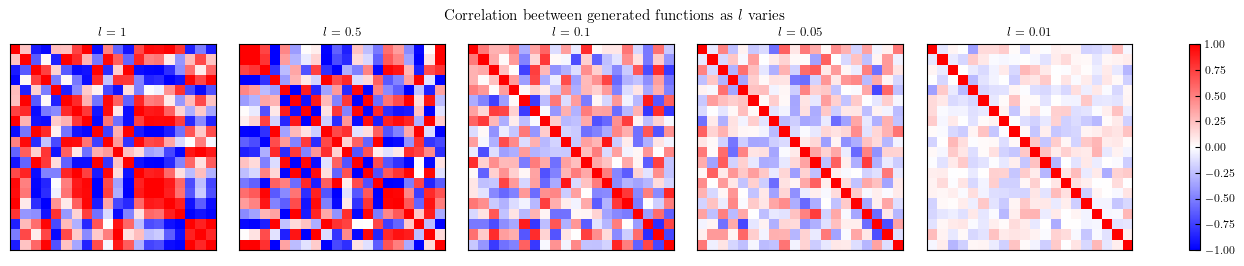

In [ ]:
f_dataset_size = 20
nt = 1000
t_array = np.linspace(0,1,nt)

# Dataset di funzioni dove ogni colonna rappresenta una funzione random su una gliglia temporale
# rappresentata dalle righe. Il dataset è dunque composto da vettori nt dimensionali.
f_dataset = np.zeros(shape=(nt,f_dataset_size))

dt = t_array[1] - t_array[0]   

fig, axes = plt.subplots(1,5,figsize=(12.5,2.5))   
index_ax = 0

generator = FunctionsGenerator(t_array)

for l in [1,0.5,0.1,0.05,0.01]:
    
    generator.l = l
    
    for index in range(f_dataset_size):
        f_dataset[:,index] = generator.generate_from_white_noise()

    # Verifico l'indipendenza tra le colonne
    f_corr = np.corrcoef(f_dataset, rowvar=False)

    im = axes[index_ax].imshow(f_corr, cmap='bwr', vmin=-1, vmax=1)
    axes[index_ax].set_title(rf"$l$ = {l}")
    axes[index_ax].set_xticks([])
    axes[index_ax].set_yticks([])
    index_ax=index_ax+1

fig.colorbar(im, ax=axes.ravel().tolist())
fig.suptitle(r"Correlation beetween generated functions as $l$ varies")
plt.savefig("assets/dataset_function_correlations.pdf")
plt.show()

Il filtro passa basso nello spazio di fourier assieme alla continuità delle funzioni introduce una correlazione nel dataset. Il filtro proietta le funzioni su un sottospazio di dimensione sempre più piccola al diminuire della sigma_filtro. Questo si vede dalla diminuzione della correlazione con l'aumento della sigma del filtro gaussiano.

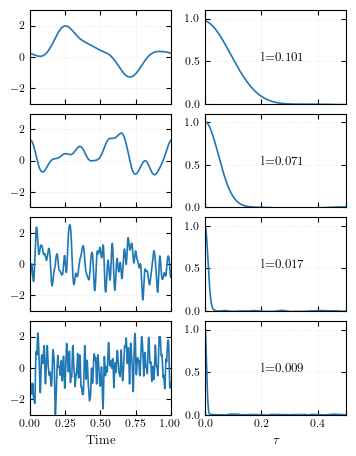

In [3]:
from scipy import signal

# Parametri simulazioni
Tf = 1
nt = 30000
t_array = np.linspace(0,Tf,nt)
sigma = 1
Nf = 1000

# Array di coorelazioni temporali
l_array = [0.1, 0.05, 0.01, 0.005]

generator = fg.FunctionsGenerator(t_array)

fig, axes = plt.subplots(4,2, sharex="col", figsize= (3.4, 4.4))

index_axes = 0

for l in l_array:
    
    f_array = np.ndarray(shape=(Nf, nt))
    var_array = np.ndarray(Nf)
    correlations_array =  np.ndarray(shape=(Nf, nt))

    generator.l = l
    
    for i in range(Nf):
        f_array[i,:] = generator.generate_from_white_noise()
        var_array[i] = np.var(f_array[i])
        correlations_array[i,:] = signal.correlate(f_array[i,:], f_array[i,:], mode="same", method="fft") / nt
    
    variance_correlation = np.var(np.mean(correlations_array, axis=0))

    lag_array = t_array - Tf/2

    axes[index_axes][1].plot(lag_array, np.mean(correlations_array, axis=0))
    axes[index_axes][1].grid()
    axes[index_axes][1].set_ylim([0,1.1])
    axes[index_axes][1].set_xlim([0,Tf/2])

    # Plot estimate of l
    axes[index_axes][1].text(0.2,0.5,f"l={variance_correlation:.3f}")

    axes[index_axes][0].plot(t_array, f_array[0,:])
    axes[index_axes][0].grid()
    axes[index_axes][0].set_ylim([-3,3])
    axes[index_axes][0].set_xlim([0,Tf])

    index_axes = index_axes + 1

axes[3][0].set_xlabel("Time")
axes[3][1].set_xlabel(r"$\tau$")

plt.savefig("assets/test_generatore_da_white_noise.pdf")
plt.show()

In [ ]:
# Plot complessità computazionale
import time

gaus_times = []
white_times = []

nt_array = np.linspace(100,1500,20, dtype=int)

for nt in nt_array:
    
    print(f"nt = {nt}")
    
    generator = FunctionsGenerator(np.linspace(0,1,nt), 0.1)
    
    start = time.time()
    for _ in range(5):
        generator.generate_from_Gaussian_Process()
    end = time.time()
    gaus_times.append((end-start)/5)

    start = time.time()
    for _ in range(5):
        generator.generate_from_white_noise()
    end = time.time()
    white_times.append((end-start)/5)

nt = 100
nt = 173
nt = 247
nt = 321
nt = 394
nt = 468
nt = 542
nt = 615
nt = 689
nt = 763
nt = 836
nt = 910
nt = 984
nt = 1057
nt = 1131
nt = 1205
nt = 1278
nt = 1352
nt = 1426
nt = 1500


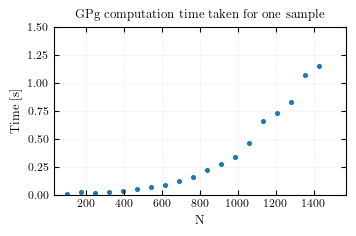

In [5]:
plt.figure()
plt.scatter(nt_array,gaus_times,s=7)
plt.xlabel("N")
plt.ylabel("Time [s]")
plt.title("GPg computation time taken for one sample")
plt.ylim([0,1.5])
plt.grid()
plt.savefig("assets/crescita_powerlaw_generatore_f.pdf")
plt.show()

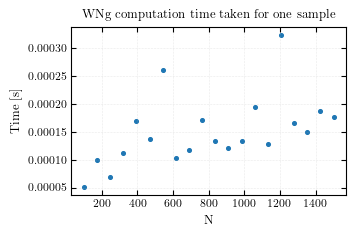

In [6]:
plt.figure()
plt.scatter(nt_array,white_times,s=7)
plt.xlabel("N")
plt.ylabel("Time [s]")
plt.title("WNg computation time taken for one sample")
plt.ylim()
plt.grid()
plt.savefig("assets/crescita_powerlaw_generatore_f_white_noise.pdf")
plt.show()